# AgroGrupos · Laboratorio de suelos
## Tarea 6 · PIAD-427 · HT-02
**Crea programas con algoritmos de aprendizaje no supervisado**

**Estudiante:** Lorena Abigail Coca Ccorpa

**Web:** https://agrogrupos.onrender.com/

### Propósito
Explorar similitudes entre análisis de suelo mediante K-Means y DBSCAN, sin proporcionar clases objetivo. PCA permite visualizar los resultados en dos dimensiones.

### Procedencia y alcance
Delgado Santiago, C. E. (2026). *TERRAGEM – Soil Physicochemical Analysis Dataset* [Conjunto de datos]. Zenodo. https://doi.org/10.5281/zenodo.19103772. Licencia CC BY 4.0. Contiene 29 registros anonimizados de análisis utilizados como casos funcionales del sistema TERRAGEM. No constituyen una muestra representativa de Mazamari ni validan recomendaciones de fertilización. Se conserva el CSV original íntegro dentro del cuaderno.

### Cómo ejecutar
Python 3.11–3.13 recomendado. Instalar, si hace falta: `%pip install numpy pandas matplotlib scikit-learn`. Después seleccionar **Kernel → Restart & Run All**. Todas las salidas mostradas se ejecutaron realmente. No requiere descargar datos.

### Flujo del proyecto
1. Revisar origen y calidad de los 29 registros.
2. Seleccionar siete variables numéricas sin etiquetas de clase.
3. Estandarizar para equilibrar sus unidades.
4. Comparar K=2…6 con silueta e inercia.
5. Interpretar perfiles, PCA y muestras aisladas.
6. Comparar con DBSCAN y analizar sensibilidad.
7. Exportar resultados y documentar límites.


In [1]:
import io, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False, 'axes.spines.right': False})
CSV_ORIGINAL = 'Sample_ID,Textural_Class,Soil_Type_App,Sand_pct,Silt_pct,Clay_pct,CaCO3_pct,CE_dS_m,pH,Available_P_ppm,Organic_Matter_pct,Available_K_ppm,Ca_meq,Mg_meq,Na_meq,K_meq,Al_H_meq,PAI_pct,CICE_meq,Cu_ppm,Zn_ppm,Mn_ppm,Fe_ppm,B_ppm,pH_Level,Salinity_Level\nM-01,Sandy Loam,Loam,66.26,23.14,10.6,<0.01,0.9,3.75,6.4,8.9,115.8,0.88,0.61,0.18,0.3,4.18,68.04,6.14,0.6,1.05,11.75,243.18,0.33,Acid,Normal\nM-02,Loamy Sand,Sandy,77.18,14.22,8.6,<0.01,0.92,3.91,4.66,8.9,118.4,1.71,0.72,0.26,0.3,3.31,52.51,6.3,0.73,1.26,7.45,107.22,0.22,Acid,Normal\nM-03,Sandy Loam,Loam,60.26,26.14,13.6,<0.01,0.71,3.78,4.69,6.55,81.2,0.7,0.37,0.26,0.21,2.66,63.37,4.2,1.01,0.33,2.34,141.12,0.16,Acid,Normal\nM-04,Sandy Loam,Loam,60.76,25.64,13.6,<0.01,0.82,4.27,4.56,9.31,115.4,2.62,0.73,0.27,0.3,1.37,25.94,5.27,1.57,1.25,18.72,105.9,0.24,Acid,Normal\nM-05,Sandy Loam,Loam,69.4,21,9.6,<0.01,0.68,3.8,5.91,11.66,69.4,0.52,0.36,0.27,0.18,4.1,75.69,5.42,0.71,0.79,1.63,126.36,0.45,Acid,Normal\nM-06,Loam,Loam,48.18,34.22,17.6,<0.01,0.9,4.2,7.26,7.93,152.4,2.12,0.85,0.17,0.39,2.05,36.78,5.58,1.19,1.2,5.4,176.64,0.34,Acid,Normal\nM-07,Loam,Loam,51.4,35,13.6,<0.01,0.66,3.76,5.97,8.28,86.6,0.81,0.48,0.28,0.22,3.65,67.09,5.44,1.07,0.81,6.47,186.48,0.33,Acid,Normal\nM-08,Sandy Loam,Loam,57.26,29.14,13.6,<0.01,0.45,4.44,4.91,8.28,94,1.95,0.54,0.3,0.24,2.51,45.29,5.54,0.42,0.91,2.69,130.8,0.3,Acid,Normal\nM-09,Sandy Loam,Loam,70.33,19.07,10.6,<0.01,0.58,4.45,5.5,7.45,125.8,2.63,0.92,0.26,0.32,1.52,26.87,5.66,1.39,0.81,8.33,121.62,0.31,Acid,Normal\nM-10,Sandy Loam,Loam,75.33,16.07,8.6,<0.01,0.7,3.71,8.13,10.48,161.6,0.51,0.63,0.28,0.41,4.48,70.99,6.32,0.11,0.84,10.79,262.32,0.2,Acid,Normal\nM-11,Loam,Loam,51.4,31,17.6,<0.01,0.52,4.3,5.23,7.24,128.2,2.53,0.77,0.29,0.33,3.04,43.75,6.95,1.07,1.56,3.28,280.02,0.21,Acid,Normal\nM-12,Loam,Loam,43.76,35.64,20.6,<0.01,0.65,4.45,6.25,5.86,70.4,4.4,1.03,0.23,0.18,0.68,10.49,6.52,1.86,2.26,23.7,180.3,0.2,Acid,Normal\nM-13,Sandy Loam,Loam,54.76,33.64,11.6,<0.01,0.57,4.42,4.3,7.45,117.2,1.81,0.69,0.29,0.3,1.44,31.81,4.54,1.98,2.78,26.28,118.5,0.23,Acid,Normal\nM-14,Sandy Loam,Loam,62.05,24.35,13.6,<0.01,0.27,4.57,7.07,4.34,69.2,1.22,0.58,0.21,0.18,1.82,45.53,4.01,2.46,1.29,32.94,129.06,0.24,Acid,Normal\nM-15,Sandy Loam,Loam,69.69,18.71,11.6,<0.01,0.26,4.54,5.34,6,90.2,1.97,0.65,0.38,0.23,1.52,31.95,4.76,2.44,1.43,11.94,180.6,0.31,Acid,Normal\nM-16,Sandy Loam,Loam,59.76,25.64,14.6,<0.01,0.44,4.63,5.47,4.55,60.2,3.3,0.95,0.34,0.15,1.06,18.34,5.8,2.32,4.88,28.5,104.34,0.35,Acid,Normal\nM-17,Sandy Loam,Loam,64.26,19.14,16.6,<0.01,0.75,3.55,5.54,10,111.2,0.49,0.46,0.16,0.28,6.08,81.35,7.47,0.28,0.61,4.56,175.08,0.3,Acid,Normal\nM-18,Sandy Loam,Loam,57.4,27.36,15.24,<0.01,0.89,4.44,9.91,8.62,140.2,4.43,1,0.26,0.36,0.91,13.1,6.96,1.39,1.51,11.6,131.16,0.24,Acid,Normal\nM-19,Sandy Clay Loam,Loam,53.4,25.36,21.24,<0.01,0.21,4.86,6.4,7.1,101.8,2.88,1.76,0.18,0.26,0.84,14.12,5.92,2.16,1.78,31.02,112.14,0.21,Acid,Normal\nM-20,Sandy Loam,Loam,64.76,20,15.24,<0.01,0.26,4.68,6.47,11.31,236.6,3.77,1.32,0.29,0.61,1.37,18.62,7.35,0.25,1.38,3.2,168.84,0.21,Acid,Normal\nM-21,Sandy Loam,Loam,56.76,28.28,14.96,<0.01,0.9,3.6,5.11,6.83,70.6,0.82,0.43,0.29,0.18,3.72,68.45,5.44,1.28,0.79,63.42,160.14,0.22,Acid,Normal\nM-22,Sandy Loam,Loam,55.76,32.28,11.96,<0.01,0.95,4.61,4.86,4.83,88,3.54,0.87,0.27,0.23,0.9,15.54,5.79,2.6,2.21,41.46,81.9,0.28,Acid,Normal\nM-23,Sandy Loam,Loam,68.4,20.64,10.96,<0.01,0.43,4.18,2.55,7.38,58.8,0.64,0.4,0.29,0.15,3.04,67.22,4.52,0.35,0.42,0.67,101.34,0.25,Acid,Normal\nM-24,Loam,Loam,50.4,34.64,14.96,<0.01,0.35,4.5,4.39,1.79,41.2,1.6,0.74,0.28,0.11,1.83,40.07,4.57,3.18,2.62,61.62,150.9,0.25,Acid,Normal\nM-25,Silt Loam,Loam,19.76,54.64,25.6,<0.01,0.24,3.95,2.93,6.34,69.4,0.54,0.32,0.03,0.18,3.57,76.93,4.64,2.02,0.79,3.76,185.7,0.15,Acid,Normal\nM-26,Sandy Loam,Loam,67.4,19,13.6,<0.01,0.85,4.11,6.75,9.52,67.4,3.23,0.86,0.23,0.17,2.36,34.39,6.85,0.47,1.01,5.84,315.72,0.3,Acid,Normal\nM-27,Loam,Loam,41.26,38.78,19.96,<0.01,0.96,4.37,5.97,6.97,110.8,3.33,0.81,0.48,0.28,1.52,23.66,6.42,1.52,3.42,16.68,218.64,0.3,Acid,Normal\nM-28,Loam,Loam,27.71,47.99,24.3,13.13,20.46,8.48,18.06,0.28,376.8,12.36,1.12,5.46,0.96,N/A,34.89,19.9,N/A,N/A,N/A,N/A,N/A,Alkaline,Saline\nM-29,Sandy Clay Loam,Loam,54.99,15.07,29.94,0.52,178.4,7.87,28.99,1.21,560,6.56,1.44,18.31,0.77,N/A,PSI:67.62,27.07,N/A,N/A,N/A,N/A,N/A,Alkaline,Saline\n'
datos = pd.read_csv(io.StringIO(CSV_ORIGINAL))
print('Dimensiones:', datos.shape)
print(datos.head().to_string(index=False))

Dimensiones: (29, 26)
Sample_ID Textural_Class Soil_Type_App  Sand_pct  Silt_pct  Clay_pct CaCO3_pct  CE_dS_m   pH  Available_P_ppm  Organic_Matter_pct  Available_K_ppm  Ca_meq  Mg_meq  Na_meq  K_meq  Al_H_meq PAI_pct  CICE_meq  Cu_ppm  Zn_ppm  Mn_ppm  Fe_ppm  B_ppm pH_Level Salinity_Level
     M-01     Sandy Loam          Loam     66.26     23.14      10.6     <0.01     0.90 3.75             6.40                8.90            115.8    0.88    0.61    0.18   0.30      4.18   68.04      6.14    0.60    1.05   11.75  243.18   0.33     Acid         Normal
     M-02     Loamy Sand         Sandy     77.18     14.22       8.6     <0.01     0.92 3.91             4.66                8.90            118.4    1.71    0.72    0.26   0.30      3.31   52.51      6.30    0.73    1.26    7.45  107.22   0.22     Acid         Normal
     M-03     Sandy Loam          Loam     60.26     26.14      13.6     <0.01     0.71 3.78             4.69                6.55             81.2    0.70    0.37    0.26 

## Diagrama de flujo del proyecto
La revisión de calidad precede a ambos algoritmos. Los resultados convergen en una interpretación común.

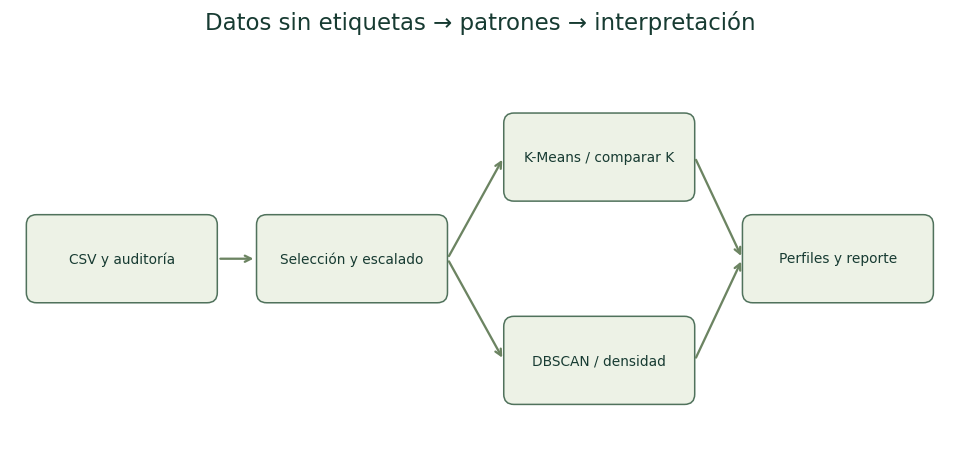

In [2]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(11, 5))
ax.set(xlim=(0, 11), ylim=(0, 5)); ax.axis('off')
boxes = [(0.3,2,'CSV y auditoría'), (3.0,2,'Selección y escalado'), (5.9,3.2,'K-Means / comparar K'), (5.9,0.8,'DBSCAN / densidad'), (8.7,2,'Perfiles y reporte')]
for x,y,t in boxes:
    ax.add_patch(FancyBboxPatch((x,y), 2, .8, boxstyle='round,pad=.12', facecolor='#edf2e6', edgecolor='#50725c'))
    ax.text(x+1,y+.4,t,ha='center',va='center',fontsize=9,color='#173b32',wrap=True)
for a,b in [(0,1),(1,2),(1,3),(2,4),(3,4)]:
    x,y,_=boxes[a]; u,v,_=boxes[b]
    ax.annotate('', xy=(u-.12,v+.4), xytext=(x+2.12,y+.4), arrowprops={'arrowstyle':'->','color':'#6c8462','lw':1.5})
ax.set_title('Datos sin etiquetas → patrones → interpretación', fontsize=15, color='#173b32'); plt.show()

## 1. Auditoría y selección
Las columnas `Textural_Class`, `Soil_Type_App`, `pH_Level` y `Salinity_Level` se excluyen del entrenamiento: no buscamos reproducir etiquetas. El ID solo identifica la muestra. Hay resultados bajo límite de detección (`<0.01`) y campos especiales (`PSI:67.62`) en otras variables; no se convierten arbitrariamente a números. Las siete seleccionadas están completas y tienen interpretación física. No se inventan valores de humedad o nitrógeno que no existen en esta fuente. Arena, limo y arcilla suman aproximadamente 100%; se excluye limo para evitar incluir las tres partes redundantes. El escalado no corrige totalmente la naturaleza composicional de la textura.

Duplicados completos: 0
IDs duplicados: 0
Faltantes en variables elegidas: {'pH': 0, 'CE_dS_m': 0, 'Organic_Matter_pct': 0, 'Available_P_ppm': 0, 'Available_K_ppm': 0, 'Sand_pct': 0, 'Clay_pct': 0}
           pH  CE_dS_m  Organic_Matter_pct  Available_P_ppm  Available_K_ppm  Sand_pct  Clay_pct
count  29.000   29.000              29.000           29.000           29.000    29.000    29.000
mean    4.489    7.437               7.081            6.882          127.200    57.243    15.316
std     1.085   33.087               2.765            5.045          105.149    12.823     5.143
min     3.550    0.210               0.280            2.550           41.200    19.760     8.600
25%     3.910    0.440               6.000            4.860           70.400    51.400    11.600
50%     4.370    0.680               7.380            5.540          101.800    57.400    13.600
75%     4.540    0.900               8.900            6.470          125.800    66.260    17.600
max     8.480  178.400    

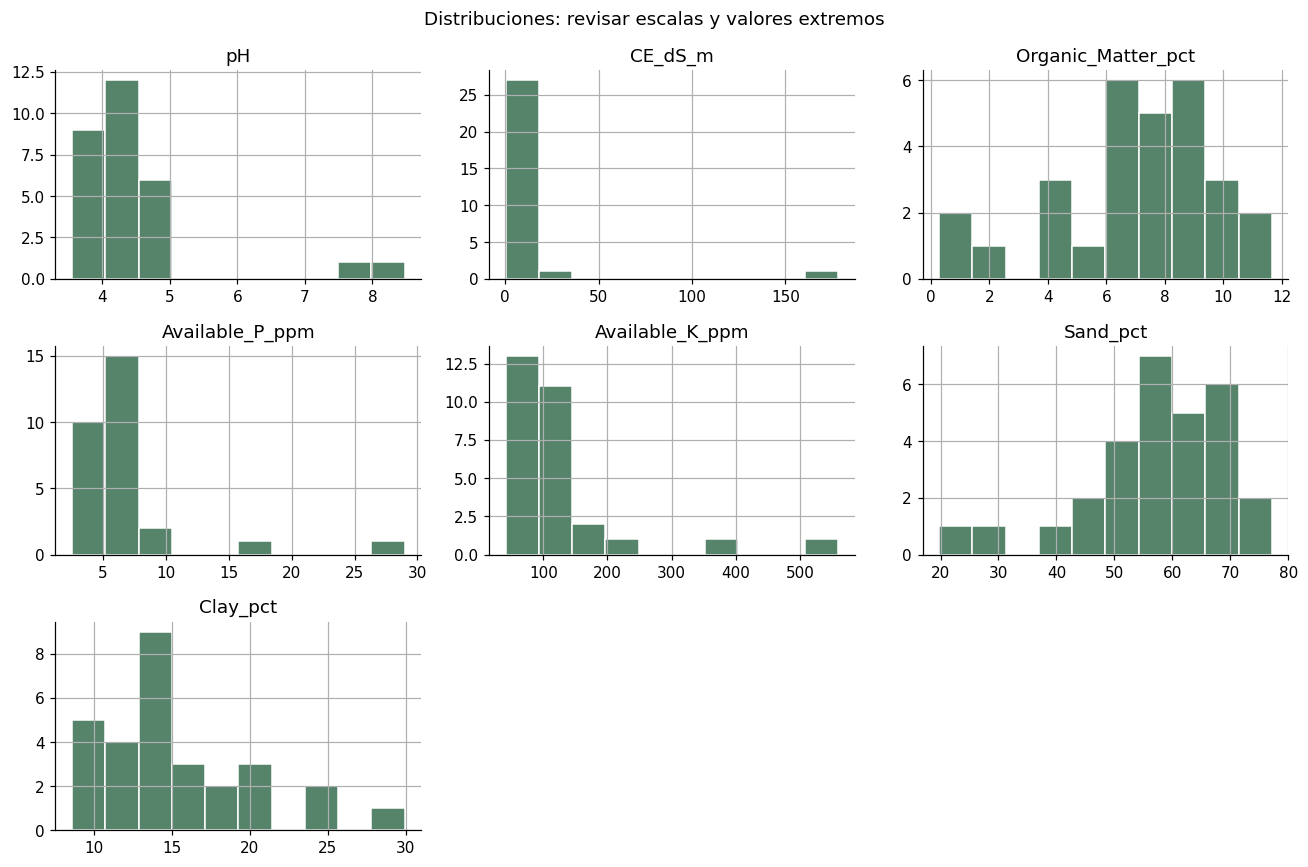

In [3]:
variables = ['pH', 'CE_dS_m', 'Organic_Matter_pct', 'Available_P_ppm', 'Available_K_ppm', 'Sand_pct', 'Clay_pct']
nombres = ['pH', 'Conductividad (dS/m)', 'Materia orgánica (%)', 'Fósforo (ppm)', 'Potasio (ppm)', 'Arena (%)', 'Arcilla (%)']
X = datos[variables].apply(pd.to_numeric, errors='coerce')
print('Duplicados completos:', datos.duplicated().sum())
print('IDs duplicados:', datos.Sample_ID.duplicated().sum())
print('Faltantes en variables elegidas:', X.isna().sum().to_dict())
assert not X.isna().any().any()
print(X.describe().round(3).to_string())
X.hist(bins=10, figsize=(12, 8), color='#56846b', edgecolor='white')
plt.suptitle('Distribuciones: revisar escalas y valores extremos'); plt.tight_layout(); plt.show()

## 2. Transformación y relaciones
Se aplica StandardScaler: z=(x−media)/desviación poblacional. Así, el potasio no domina solamente porque se expresa en centenas. La conductividad extrema puede influir mucho aun después del escalado; después lo evaluamos mediante sensibilidad. Ajustamos grupos exploratorios con todos los datos; no se reporta accuracy ni una partición supervisada de entrenamiento/prueba porque no existe una clase verdadera objetivo.

Media escalada: [-0.  0. -0. -0. -0. -0. -0.]


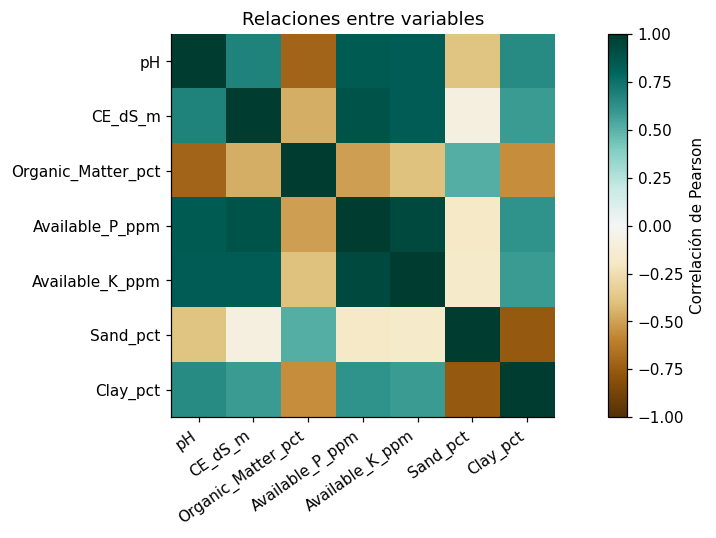

In [4]:
escalador = StandardScaler()
Z = escalador.fit_transform(X)
print('Media escalada:', Z.mean(axis=0).round(8))
fig, ax = plt.subplots()
im = ax.imshow(X.corr(), cmap='BrBG', vmin=-1, vmax=1)
ax.set_xticks(range(len(variables)), variables, rotation=35, ha='right')
ax.set_yticks(range(len(variables)), variables)
fig.colorbar(im, ax=ax, label='Correlación de Pearson'); ax.set_title('Relaciones entre variables'); plt.tight_layout(); plt.show()

## 3. K-Means y elección de K
K-Means alterna asignar cada muestra al centro más cercano y recalcular centros, minimizando la suma de distancias cuadráticas (inercia). Se usan 30 inicializaciones y semilla 42. La silueta compara cohesión y separación: cerca de 1 indica mayor separación geométrica, 0 solapamiento, valores negativos posibles asignaciones poco coherentes. No es porcentaje de aciertos. Su máximo es una pista exploratoria, no prueba de que ese K tenga significado agronómico.

 K  Inercia  Silueta
 2  85.6677   0.7223
 3  60.6171   0.3269
 4  41.6258   0.3144
 5  30.1420   0.2460
 6  24.0085   0.2395
K sugerido: 2


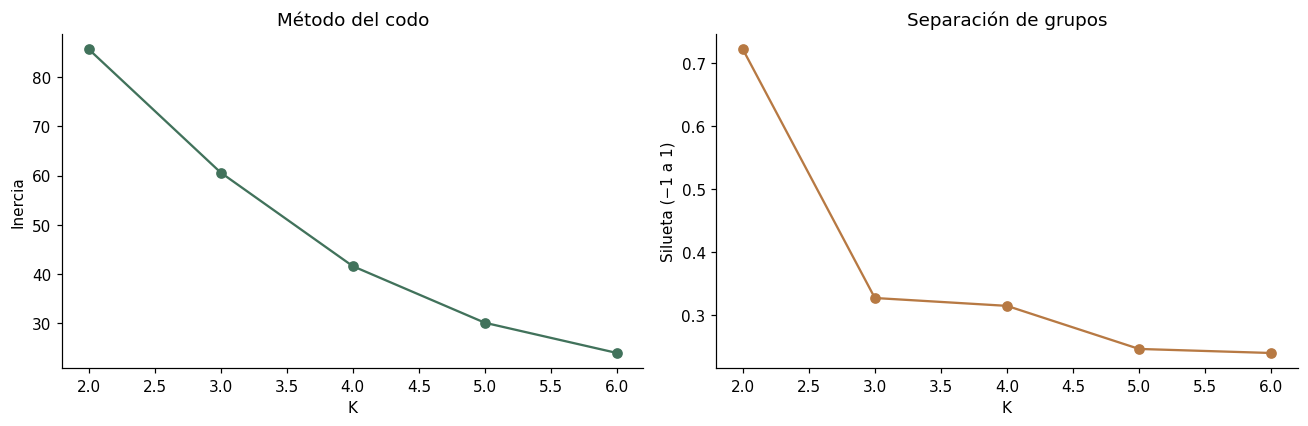

In [5]:
modelos, resultados = {}, []
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, n_init=30, random_state=42).fit(Z)
    modelos[k] = modelo
    resultados.append({'K': k, 'Inercia': modelo.inertia_, 'Silueta': silhouette_score(Z, modelo.labels_)})
evaluacion = pd.DataFrame(resultados)
k_elegido = int(evaluacion.loc[evaluacion.Silueta.idxmax(), 'K'])
modelo = modelos[k_elegido]
grupos = modelo.labels_
print(evaluacion.round(4).to_string(index=False)); print('K sugerido:', k_elegido)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(evaluacion.K, evaluacion.Inercia, 'o-', color='#41725b'); axes[0].set(title='Método del codo', xlabel='K', ylabel='Inercia')
axes[1].plot(evaluacion.K, evaluacion.Silueta, 'o-', color='#b77943'); axes[1].set(title='Separación de grupos', xlabel='K', ylabel='Silueta (−1 a 1)')
plt.tight_layout(); plt.show()

## 4. Visualización e interpretación
PCA resume la variación sin usar etiquetas. Agrupamos en las siete dimensiones estandarizadas, no solo en los dos ejes dibujados. Los números de grupo son identificadores arbitrarios, no niveles de calidad. Revisar si existen grupos unitarios y si M-28/M-29 explican gran parte de la separación.

Varianza explicada por ejes: [0.6554 0.2003]
Promedios en unidades originales:
          pH  CE_dS_m  Organic_Matter_pct  Available_P_ppm  Available_K_ppm  Sand_pct  Clay_pct
Grupo                                                                                          
1      4.216    0.623               7.551            5.649          101.926     58.42    14.441
2      8.175   99.430               0.745           23.525          468.400     41.35    27.120
Tamaños: {1: 27, 2: 2}


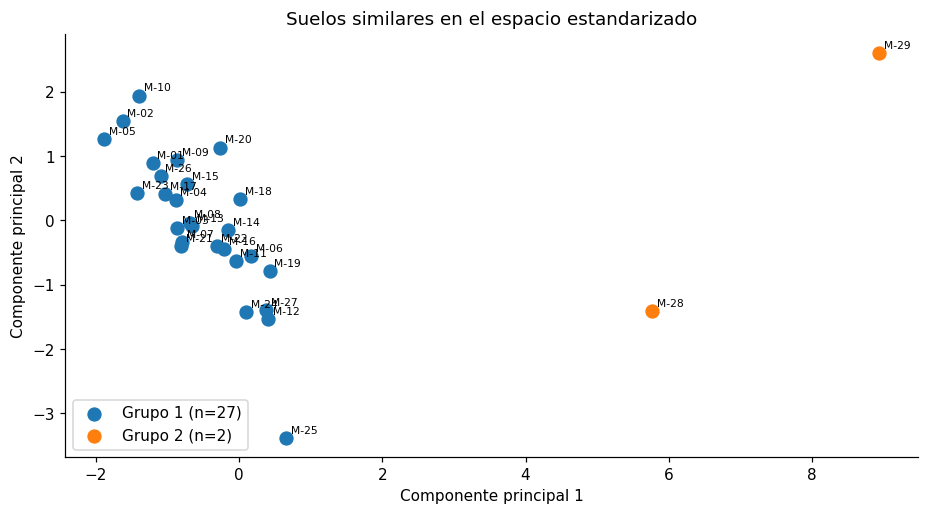

In [6]:
pca = PCA(n_components=2)
proyeccion = pca.fit_transform(Z)
print('Varianza explicada por ejes:', pca.explained_variance_ratio_.round(4))
fig, ax = plt.subplots()
for g in np.unique(grupos):
    mask = grupos == g
    ax.scatter(*proyeccion[mask].T, s=70, label=f'Grupo {g+1} (n={mask.sum()})')
for i, ident in enumerate(datos.Sample_ID):
    ax.annotate(ident, proyeccion[i], fontsize=7, xytext=(3,3), textcoords='offset points')
ax.set(xlabel='Componente principal 1', ylabel='Componente principal 2', title='Suelos similares en el espacio estandarizado'); ax.legend(); plt.show()
perfiles = X.assign(Grupo=grupos+1).groupby('Grupo').mean()
print('Promedios en unidades originales:'); print(perfiles.round(3).to_string())
print('Tamaños:', pd.Series(grupos+1).value_counts().sort_index().to_dict())

## 5. Segundo algoritmo: DBSCAN
DBSCAN agrupa por densidad y marca ruido con −1. No exige indicar K. Se prueban varios radios `eps` y `min_samples=3`; demasiados puntos de ruido o un solo grupo no significan un fallo del código. La silueta se calcula solo si quedan al menos dos grupos no ruidosos y más observaciones que grupos. No se interpreta ruido como suelo malo ni diagnóstico clínico/agronómico.

 eps  grupos  ruido  silueta_sin_ruido
 0.7       2     23             0.5649
 1.0       3      9             0.3304
 1.4       1      4                NaN
 1.8       1      3                NaN
 2.2       1      3                NaN


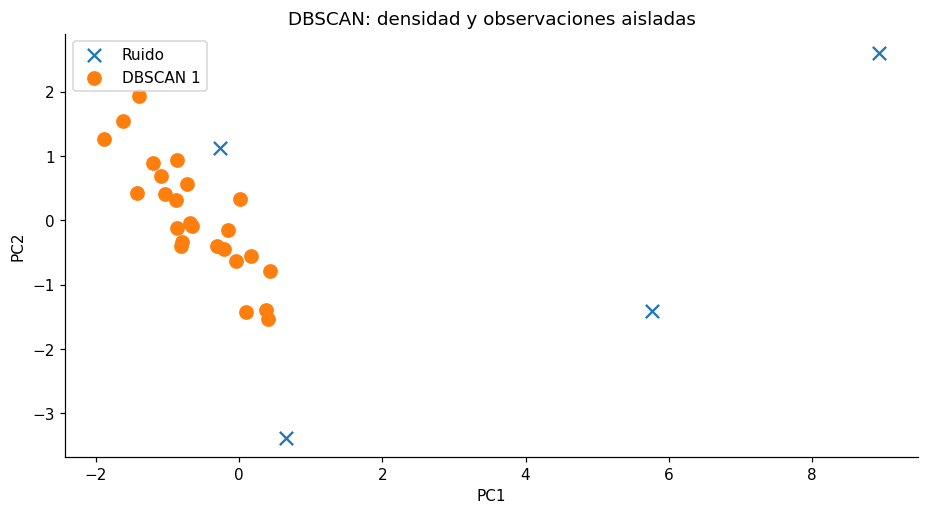

In [7]:
comparacion = []
for eps in [0.7, 1.0, 1.4, 1.8, 2.2]:
    lab = DBSCAN(eps=eps, min_samples=3).fit_predict(Z)
    validos = lab >= 0
    n_grupos = len(set(lab[validos]))
    sil = silhouette_score(Z[validos], lab[validos]) if 1 < n_grupos < validos.sum() else np.nan
    comparacion.append({'eps': eps, 'grupos': n_grupos, 'ruido': int((~validos).sum()), 'silueta_sin_ruido': sil})
print(pd.DataFrame(comparacion).round(4).to_string(index=False))
lab_db = DBSCAN(eps=1.4, min_samples=3).fit_predict(Z)
fig, ax = plt.subplots()
for g in np.unique(lab_db):
    mask = lab_db == g
    ax.scatter(*proyeccion[mask].T, label='Ruido' if g == -1 else f'DBSCAN {g+1}', marker='x' if g == -1 else 'o', s=75)
ax.legend(); ax.set(title='DBSCAN: densidad y observaciones aisladas', xlabel='PC1', ylabel='PC2'); plt.show()

## 6. Sensibilidad y estabilidad
Se compara la asignación con diez semillas al mismo K (Adjusted Rand Index: 1=coincidencia completa, ajustada por azar). Esto mide estabilidad en esta muestra, no generalización. También se repite la exploración sin M-28/M-29, identificadas previamente por su elevada conductividad. No se eliminan del análisis principal: la comparación muestra cuánto depende el resultado de esos dos casos.

In [8]:
aris = [adjusted_rand_score(grupos, KMeans(n_clusters=k_elegido, n_init=30, random_state=s).fit_predict(Z)) for s in range(10)]
print('ARI semillas: mínimo / media:', round(min(aris),4), round(np.mean(aris),4))
normal = ~datos.Sample_ID.isin(['M-28', 'M-29'])
Zn = StandardScaler().fit_transform(X.loc[normal])
sensibilidad = []
for k in range(2,7):
    g = KMeans(n_clusters=k, n_init=30, random_state=42).fit_predict(Zn)
    sensibilidad.append({'K':k, 'Silueta sin M-28/M-29':silhouette_score(Zn,g)})
print(pd.DataFrame(sensibilidad).round(4).to_string(index=False))
print('Conclusión: contrastar tamaño de grupos, perfiles y estabilidad; no elegir solo el número mayor.')

ARI semillas: mínimo / media: 1.0 1.0
 K  Silueta sin M-28/M-29
 2                 0.2026
 3                 0.2015
 4                 0.2158
 5                 0.2151
 6                 0.1844
Conclusión: contrastar tamaño de grupos, perfiles y estabilidad; no elegir solo el número mayor.


## 7. Exportación opcional
La siguiente celda prepara un CSV y un modelo JSON reproducible. Cambiar `GUARDAR` a True si se desea escribirlos en el directorio del cuaderno. El modelo conserva variables, media, escala y centroides; una nueva muestra necesita exactamente las mismas unidades.

In [9]:
GUARDAR = False
salida = datos[['Sample_ID'] + variables].copy()
salida['Grupo'] = grupos + 1
modelo_exportable = {'variables':variables, 'media':escalador.mean_.tolist(), 'escala':escalador.scale_.tolist(), 'centroides':modelo.cluster_centers_.tolist(), 'K':k_elegido}
if GUARDAR:
    salida.to_csv('AgroGrupos_resultados.csv', index=False)
    with open('AgroGrupos_modelo.json', 'w', encoding='utf-8') as f:
        json.dump(modelo_exportable, f, ensure_ascii=False, indent=2)
print(salida.head().to_string(index=False))

Sample_ID   pH  CE_dS_m  Organic_Matter_pct  Available_P_ppm  Available_K_ppm  Sand_pct  Clay_pct  Grupo
     M-01 3.75     0.90                8.90             6.40            115.8     66.26      10.6      1
     M-02 3.91     0.92                8.90             4.66            118.4     77.18       8.6      1
     M-03 3.78     0.71                6.55             4.69             81.2     60.26      13.6      1
     M-04 4.27     0.82                9.31             4.56            115.4     60.76      13.6      1
     M-05 3.80     0.68               11.66             5.91             69.4     69.40       9.6      1


## Manual de la web
1. Abrir https://agrogrupos.onrender.com/. Se cargan los 29 casos incluidos.
2. Elegir **K-Means** o **DBSCAN** y ajustar sus controles.
3. Pulsar **Analizar suelos**. Se recalculan grupos y métricas.
4. Cambiar los ejes del gráfico; tocar una muestra para ver sus medidas.
5. Revisar perfiles promedio y la tabla filtrable.
6. Descargar resultados CSV o el reporte imprimible.
7. Para datos propios, descargar la plantilla y cargar CSV UTF-8 separado por comas. Usar punto decimal y las mismas siete columnas/unidades; `Sample_ID` identifica cada fila. Entre 8 y 500 filas, valores completos, IDs únicos. No se requieren categorías previas.
8. Restaurar los datos originales mediante **Restaurar demo**.

### Relación web–cuaderno
El modo inicial de la web utiliza los modelos exactos exportados de scikit-learn para K=2…6. Para CSV propios, la web implementa Lloyd con inicialización lejana, 20 reinicios deterministas y hasta 200 iteraciones; puede obtener otra solución local respecto de scikit-learn. La web calcula silueta con las siete dimensiones estandarizadas. DBSCAN usa distancia euclídea en ese mismo espacio.

## Conclusiones y límites
- Se implementaron dos algoritmos no supervisados y una proyección PCA.
- Los resultados dependen de variables, escalado y parámetros; los grupos no son clases agronómicas universales.
- La muestra pequeña y sus casos extremos limitan la representatividad. No se fabrican porcentajes de precisión.
- Agrupar permite orientar revisión de análisis similares, pero no establece automáticamente cultivo adecuado, dosis de cal ni fertilización.
- Para ampliar el proyecto: incorporar mediciones locales con métodos de laboratorio documentados, más muestras y revisión de un especialista.

## Bibliografía breve (APA)
Delgado Santiago, C. E. (2026). *TERRAGEM – Soil Physicochemical Analysis Dataset* [Conjunto de datos]. Zenodo. https://doi.org/10.5281/zenodo.19103772

Scikit-learn developers. (s. f.). *Clustering*. https://scikit-learn.org/stable/modules/clustering.html

Scikit-learn developers. (s. f.). *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

Scikit-learn developers. (s. f.). *PCA*. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
